In [2]:
import numpy as np
from scipy.optimize import nnls, minimize
import matplotlib.pyplot as plt

In [3]:
# ============================================================
# 1. Compute A
# ============================================================

def compute_A(X, Z):
    """
    Compute the coefficients A that represent each observation
    as a convex combination of the archetypes.
    """
    n = X.shape[0]
    p = Z.shape[0]

    A = np.zeros((n, p))

    for i in range(n):
        A[i], _ = convex_least_squares(X[i], Z)

    return A

In [4]:
# ============================================================
# 2. Convex Least Squares
# ============================================================

def convex_least_squares(x, Z):
    """
    Solve the convex least-squares problem:

        min ||x - Z.T @ a||^2

    subject to:

        a >= 0
        sum(a) = 1
    """
    p = Z.shape[0]    
    T = Z.T

    def objective(a):
        diff = x - T @ a
        return np.dot(diff, diff)

    def jacobian(a):
        return -2 * T.T @ (x - T @ a)

    constraints = {'type': 'eq', 'fun': lambda a: np.sum(a) - 1.0}
    bounds = [(0, None) for _ in range(p)]
    a0 = np.full(p, 1.0 / p)

    res = minimize(
        objective,
        a0,
        method='SLSQP',
        jac=jacobian,
        bounds=bounds,
        constraints=constraints,
        options={'ftol': 1e-9, 'maxiter': 500}
    )

    a = np.maximum(0, res.x)
    a_sum = a.sum()
    if a_sum > 0:
        a /= a_sum
    else:
        a = a0

    return a, res.fun

In [5]:
# ============================================================
# 3. Compute Z
# ============================================================

def compute_Z(B, X):
    """
    Compute the archetypes from beta and X.

        Z = B @ X
    """
    return B @ X

In [6]:
# ============================================================
# 4. Compute beta for one archetype
# ============================================================

def compute_B(X, A, Z, k, M=1.0):
    n, m = X.shape

    numerator = np.zeros(m)
    denominator = 0.0

    for i in range(n):
        if A[i, k] > 1e-8:
            contribution = np.zeros(m)
            for l in range(Z.shape[0]):
                if l != k:
                    contribution += A[i, l] * Z[l]

            v_i = (X[i] - contribution) / A[i, k]
            numerator += (A[i, k] ** 2) * v_i
            denominator += A[i, k] ** 2

    if denominator == 0:
        return np.ones(n) / n

    v = numerator / denominator

    T = X.T
    T_augmented = np.vstack([T, M * np.ones((1, n))])
    v_augmented = np.append(v, M)

    try:
        B_k, _ = nnls(T_augmented, v_augmented, maxiter=5000)
    except RuntimeError:
        B_k = np.ones(n) / n

    sum_B = np.sum(B_k)
    if sum_B > 0:
        B_k = B_k / sum_B

    return B_k

In [7]:
# ============================================================
# 5. Compute RSS
# ============================================================

def compute_rss(X, A, Z):
    """
    Compute the reconstruction error:

        RSS = sum ||X - A @ Z||^2
    """
    X_reconstructed = A @ Z
    residuals = X - X_reconstructed
    return np.sum(residuals ** 2)

In [8]:
# ============================================================
# 6. One alternating iteration
# ============================================================

def one_iteration(X, Z, tol=1e-6, max_inner_iter=100):
    A = compute_A(X, Z)
    p = Z.shape[0]
    B = np.zeros((p, X.shape[0]))

    Z_new = Z.copy()
    previous_rss = np.inf

    for inner_iteration in range(max_inner_iter):
        for k in range(p):
            B[k] = compute_B(X, A, Z_new, k)
            Z_new[k] = compute_Z(B[k:k+1], X)[0]

        rss = compute_rss(X, A, Z_new)
        improvement = previous_rss - rss

        if improvement < tol:
            break

        previous_rss = rss

    A_new = compute_A(X, Z_new)
    rss = compute_rss(X, A_new, Z_new)

    return A_new, B, Z_new, rss

In [9]:
# ============================================================
# 7. Complete Weighted Archetypal Analysis (con W)
# ============================================================

def weighted_archetypal_analysis(
    X,
    p,
    W=None,
    max_iter=100,
    max_inner_iter=100,
    tol=1e-4
):
    """
    Realiza el análisis arquetípico ponderado mediante preprocesamiento:
        X_tilde = W @ X
    """
    X = np.asarray(X, dtype=float)
    n = X.shape[0]

    if W is None:
        W = np.eye(n)
    else:
        W = np.asarray(W, dtype=float)

    # PASO 1: Preprocesamiento de los datos con W
    X_tilde = W @ X

    rng = np.random.default_rng(42)
    B = rng.dirichlet(np.ones(n), size=p)

    # Calculamos los arquetipos iniciales sobre el espacio transformado
    Z = compute_Z(B, X_tilde)
    Z_initial = Z.copy()

    previous_rss = np.inf

    for iteration in range(max_iter):
        # Realizamos las iteraciones alternantes sobre X_tilde
        A, B, Z_new, rss = one_iteration(
            X_tilde,
            Z,
            tol=tol,
            max_inner_iter=max_inner_iter
        )

        improvement = previous_rss - rss

        print(
            f"Iteration {iteration + 1}: "
            f"RSS (weighted) = {rss:.6f}, "
            f"improvement = {improvement:.6f}"
        )

        if improvement < tol:
            Z = Z_new
            break

        Z = Z_new
        previous_rss = rss

    # PASO 2: Postprocesamiento / obtención de arquetipos finales
    # Z contiene los arquetipos ponderados finales (Z_tilde)
    return A, B, Z, Z_initial, rss

Shape de X: (300, 2)
Iteration 1: RSS (weighted) = 1249.123566, improvement = inf
Iteration 2: RSS (weighted) = 513.191346, improvement = 735.932220
Iteration 3: RSS (weighted) = 206.329520, improvement = 306.861826
Iteration 4: RSS (weighted) = 78.042538, improvement = 128.286982
Iteration 5: RSS (weighted) = 41.917599, improvement = 36.124940
Iteration 6: RSS (weighted) = 28.549993, improvement = 13.367606
Iteration 7: RSS (weighted) = 22.182331, improvement = 6.367662
Iteration 8: RSS (weighted) = 18.835750, improvement = 3.346581
Iteration 9: RSS (weighted) = 16.649239, improvement = 2.186510
Iteration 10: RSS (weighted) = 14.990282, improvement = 1.658957
Iteration 11: RSS (weighted) = 13.679538, improvement = 1.310745
Iteration 12: RSS (weighted) = 12.625175, improvement = 1.054362
Iteration 13: RSS (weighted) = 11.765243, improvement = 0.859932
Iteration 14: RSS (weighted) = 11.207297, improvement = 0.557946
Iteration 15: RSS (weighted) = 10.963819, improvement = 0.243478
Iterat

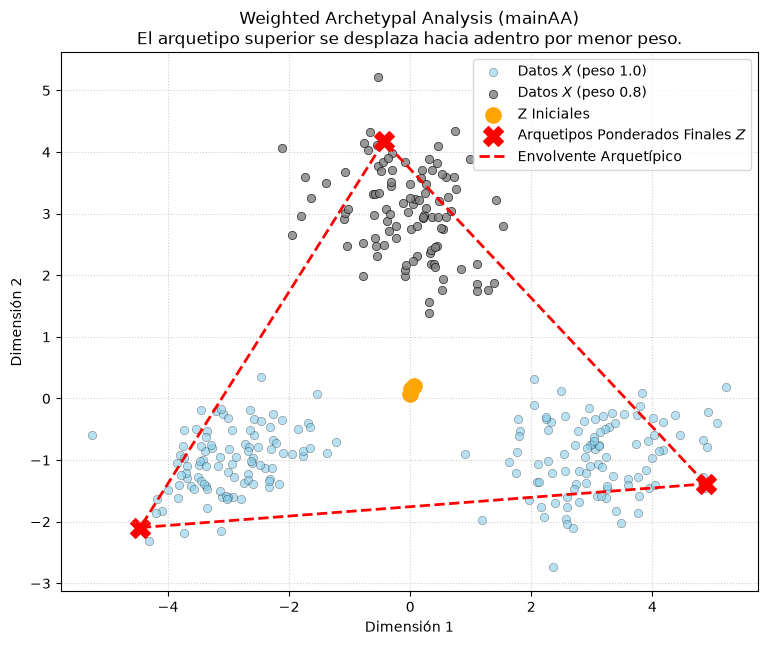

In [10]:
# ============================================================
# 8. Prueba con Gráfica (Estilo Figura 3 del artículo)
# ============================================================

if __name__ == "__main__":
    rng = np.random.default_rng(42)
    n_per_cluster = 100

    # Generación de datos sintéticos en 3 clusters (3 Gaussianas)
    X1 = rng.multivariate_normal(
        mean=[-3.0, -1.0],
        cov=[[0.6, 0.2], [0.2, 0.4]],
        size=n_per_cluster
    )
    X2 = rng.multivariate_normal(
        mean=[0.0, 3.0],
        cov=[[0.5, -0.1], [-0.1, 0.5]],
        size=n_per_cluster
    )
    X3 = rng.multivariate_normal(
        mean=[3.0, -1.0],
        cov=[[0.6, 0.15], [0.15, 0.5]],
        size=n_per_cluster
    )

    X = np.vstack([X1, X2, X3])
    n_total = X.shape[0]
    print("Shape de X:", X.shape)

    # Definir pesos W (Matriz diagonal)
    # Reducimos el peso a 0.8 en los puntos pertenecientes al cluster superior (X2)
    weights = np.ones(n_total)
    weights[n_per_cluster:2*n_per_cluster] = 0.8  
    W = np.diag(weights)

    p_archetypes = 3
    A, B, Z, Z_initial, rss = weighted_archetypal_analysis(
        X, 
        p=p_archetypes, 
        W=W, 
        max_iter=100, 
        max_inner_iter=100, 
        tol=1e-4
    )

    # 3. Mostrar Resultados y Gráfica
    plt.figure(figsize=(9, 7))

    normal_mask = weights == 1.0
    lower_mask = weights < 1.0

    # Puntos con peso estándar (1.0)
    plt.scatter(
        X[normal_mask, 0], X[normal_mask, 1],
        c='skyblue', alpha=0.6, edgecolors='k', linewidths=0.3,
        label='Datos $X$ (peso 1.0)'
    )
    # Puntos con menor peso (0.8) en el cluster superior
    plt.scatter(
        X[lower_mask, 0], X[lower_mask, 1],
        c='gray', alpha=0.8, edgecolors='k', linewidths=0.5,
        label='Datos $X$ (peso 0.8)'
    )

    plt.scatter(
        Z_initial[:, 0], Z_initial[:, 1],
        c='orange', s=120, marker='o',
        label='Z Iniciales'
    )
    plt.scatter(
        Z[:, 0], Z[:, 1],
        c='red', s=200, marker='X',
        label='Arquetipos Ponderados Finales $Z$'
    )

    # Envolvente convexa de los arquetipos ponderados
    Z_polygon = np.vstack([Z, Z[0]])
    plt.plot(
        Z_polygon[:, 0], Z_polygon[:, 1],
        'r--', linewidth=2,
        label='Envolvente Arquetípico'
    )

    plt.title(
        f"Weighted Archetypal Analysis (mainAA)\n"
        f"El arquetipo superior se desplaza hacia adentro por menor peso."
    )
    plt.xlabel("Dimensión 1")
    plt.ylabel("Dimensión 2")
    plt.legend(loc='upper right')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()